In [1]:
!.venv\Scripts\activate


In [2]:
# Листинг 2 — Импорт библиотек, версии и единый seed

# Стандартные модули нужны для копирования параметров и фиксации случайности.
import copy
import random
import sys
from pathlib import Path
# Библиотеки анализа данных и визуализации.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# Компоненты scikit-learn для preprocessing, baseline и метрик.
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
# PyTorch предоставляет автоматическое дифференцирование и оптимизаторы.
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset


In [3]:
DATA_DIR = Path("ML_Lab2_Datasets")
VARIANT = 4
RANDOM_STATE = 1000 + VARIANT

In [4]:
def set_seed(seed):
    # Фиксирует генераторы Python, NumPy и PyTorch
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # warn_only сохраняет запуск, если операция не имеет детерминированного варианта.
    torch.use_deterministic_algorithms(True, warn_only=True)
    
set_seed(RANDOM_STATE)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# Эти строки следует сохранить в начале notebook для воспроизводимости.
print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("PyTorch:", torch.__version__)
print("Устройство:", DEVICE)

Python: 3.14.8 (tags/v3.14.8:8e6e75d, Sep 30 2026, 18:19:33) [MSC v.1944 64 bit (AMD64)]
NumPy: 2.5.3
Pandas: 3.0.6
PyTorch: 2.14.1+cu126
Устройство: cuda


In [5]:
# Листинг 4 — Загрузка CSV-файла по манифесту

from pathlib import Path
import pandas as pd
  
# Манифест связывает вариант, файл, OpenML data_id и целевой столбец.
manifest = pd.read_csv(DATA_DIR / "manifest.csv")
row = manifest.loc[manifest["variant"] == VARIANT].iloc[0]
data_path = DATA_DIR / row["file_name"]
target_column = row["target_column"]
 
# В каждом CSV целевая переменная уже включена в общую таблицу.
frame = pd.read_csv(data_path)
X = frame.drop(columns=[target_column])
y = frame[target_column]
 
# В варианте 15 исходный набор содержит объекты без метки класса.
labeled_mask = y.notna()
if not labeled_mask.all():
    print("Удалено объектов без целевой метки:", int((~labeled_mask).sum()))
    X = X.loc[labeled_mask].reset_index(drop=True)
    y = y.loc[labeled_mask].reset_index(drop=True)
 
print("Файл:", data_path)
print("Размер X:", X.shape)
print("Целевой столбец:", target_column)


Файл: ML_Lab2_Datasets\variant_04.csv
Размер X: (2000, 64)
Целевой столбец: class


In [6]:
# Листинг 22 — Preprocessing смешанных признаков варианта

# X и y загружены из CSV своего варианта по листингу 4.
X_trainval_raw, X_test_raw, y_trainval_raw, y_test_raw = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)
X_train_raw, X_val_raw, y_train_raw, y_val_raw = train_test_split(
    X_trainval_raw,
    y_trainval_raw,
    test_size=0.25,
    stratify=y_trainval_raw,
    random_state=RANDOM_STATE,
)
 
# Формируем отдельные цепочки для числовых и категориальных столбцов.
numeric_columns = X_train_raw.select_dtypes(include="number").columns.tolist()
categorical_columns = [
    column for column in X_train_raw.columns if column not in numeric_columns
]
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
 
transformers = []
if numeric_columns:
    transformers.append(("numeric", numeric_pipeline, numeric_columns))
if categorical_columns:
    transformers.append(("categorical", categorical_pipeline, categorical_columns))
preprocessor = ColumnTransformer(transformers, sparse_threshold=0.0)
 
# fit выполняется только на Train; Validation и Test лишь преобразуются.
X_train = np.asarray(
    preprocessor.fit_transform(X_train_raw), dtype=np.float32
)
X_val = np.asarray(preprocessor.transform(X_val_raw), dtype=np.float32)
X_test = np.asarray(preprocessor.transform(X_test_raw), dtype=np.float32)
 
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train_raw).astype(np.int64)
y_val = label_encoder.transform(y_val_raw).astype(np.int64)
y_test = label_encoder.transform(y_test_raw).astype(np.int64)


In [7]:
# Листинг 7 — Линейный baseline на validation
# Baseline показывает, сколько качества даёт линейная граница решений.
baseline = LogisticRegression(
    max_iter=2000,
    random_state=RANDOM_STATE,
)
baseline.fit(X_train, y_train)
 
# Validation используется для сопоставления с MLP; test пока остаётся закрытым.
baseline_val_pred = baseline.predict(X_val)
baseline_result = {
    "model": "LogisticRegression",
    "accuracy": accuracy_score(y_val, baseline_val_pred),
    "macro_f1": f1_score(y_val, baseline_val_pred, average="macro"),
}
print(pd.Series(baseline_result))



model       LogisticRegression
accuracy                0.9325
macro_f1              0.932731
dtype: object


In [8]:
# Листинг 8 — Прямой и обратный проход двухслойной сети

def stable_softmax(logits):
    """Вычисляет Softmax устойчиво к большим значениям логитов."""
    shifted = logits - logits.max(axis=1, keepdims=True)
    exponents = np.exp(shifted)
    return exponents / exponents.sum(axis=1, keepdims=True)
 
 
def initialize_numpy_mlp(n_inputs, n_hidden, n_classes, seed):
    """Создаёт веса He/Xavier и нулевые смещения."""
    rng = np.random.default_rng(seed)
    return {
        "W1": rng.normal(0, np.sqrt(2 / n_inputs), (n_inputs, n_hidden)),
        "b1": np.zeros(n_hidden),
        "W2": rng.normal(0, np.sqrt(1 / n_hidden), (n_hidden, n_classes)),
        "b2": np.zeros(n_classes),
    }
 
 
def forward_numpy(X, parameters):
    """Выполняет прямой проход и сохраняет значения для BackProp."""
    Z1 = X @ parameters["W1"] + parameters["b1"]
    H = np.maximum(Z1, 0.0)                 # ReLU
    logits = H @ parameters["W2"] + parameters["b2"]
    probabilities = stable_softmax(logits)
    cache = {"X": X, "Z1": Z1, "H": H, "P": probabilities}
    return probabilities, cache
 
 
def cross_entropy_numpy(probabilities, y, parameters, l2=0.0):
    """Считает среднюю кросс-энтропию и L2-штраф для весов."""
    row_indices = np.arange(len(y))
    data_loss = -np.log(probabilities[row_indices, y] + 1e-12).mean()
    penalty = 0.5 * l2 * (
        np.sum(parameters["W1"] ** 2) + np.sum(parameters["W2"] ** 2)
    )
    return data_loss + penalty
 
 
def backward_numpy(cache, y, parameters, l2=0.0):
    """Вычисляет аналитические градиенты по правилу цепочки."""
    X, Z1, H, probabilities = (
        cache["X"], cache["Z1"], cache["H"], cache["P"]
    )
    batch_size = len(y)
 
    # Для связки Softmax + CrossEntropy градиент по логитам имеет простой вид.
    dZ2 = probabilities.copy()
    dZ2[np.arange(batch_size), y] -= 1.0
    dZ2 /= batch_size
 
    dW2 = H.T @ dZ2 + l2 * parameters["W2"]
    db2 = dZ2.sum(axis=0)
    dH = dZ2 @ parameters["W2"].T
 
    # Производная ReLU равна единице только для положительных входов.
    dZ1 = dH * (Z1 > 0)
    dW1 = X.T @ dZ1 + l2 * parameters["W1"]
    db1 = dZ1.sum(axis=0)
    return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}



In [9]:
# Листинг 9 — Проверка BackProp конечными разностями
def gradient_check(X, y, parameters, checks=12, epsilon=1e-5):
    """Сравнивает несколько аналитических градиентов с численными."""
    probabilities, cache = forward_numpy(X, parameters)
    analytical = backward_numpy(cache, y, parameters)
    rng = np.random.default_rng(RANDOM_STATE)
    rows = []
 
    for _ in range(checks):
        # Случайно выбираем тензор параметров и один его элемент.
        name = rng.choice(list(parameters))
        parameter = parameters[name]
        flat_index = int(rng.integers(parameter.size))
        index = np.unravel_index(flat_index, parameter.shape)
        original_value = parameter[index]
 
        # Центральная разность использует две оценки функции потерь.
        parameter[index] = original_value + epsilon
        plus_probabilities, _ = forward_numpy(X, parameters)
        loss_plus = cross_entropy_numpy(plus_probabilities, y, parameters)
 
        parameter[index] = original_value - epsilon
        minus_probabilities, _ = forward_numpy(X, parameters)
        loss_minus = cross_entropy_numpy(minus_probabilities, y, parameters)
        parameter[index] = original_value       # обязательно восстанавливаем вес
 
        numerical = (loss_plus - loss_minus) / (2 * epsilon)
        analytic = analytical[name][index]
        relative_error = abs(numerical - analytic) / (
            abs(numerical) + abs(analytic) + 1e-12
        )
        rows.append((name, str(index), analytic, numerical, relative_error))
 
    return pd.DataFrame(
        rows,
        columns=["parameter", "index", "analytical", "numerical", "relative_error"],
    )
 
 
# Проверка выполняется на малой сети и нескольких объектах.
# Размеры сети определяются по подготовленным данным текущего набора.
check_parameters = initialize_numpy_mlp(
    X_train.shape[1], 5, len(label_encoder.classes_), RANDOM_STATE
)
check_table = gradient_check(X_train[:8], y_train[:8], check_parameters)
print(check_table)
print("Максимальная относительная ошибка:", check_table["relative_error"].max())

   parameter                       index  analytical  numerical  \
0         W2  (np.int64(0), np.int64(0))    0.284840   0.284840   
1         W1  (np.int64(8), np.int64(1))    0.016103   0.016103   
2         W1  (np.int64(8), np.int64(4))    0.047225   0.047225   
3         b2              (np.int64(3),)    0.014238   0.014238   
4         b1              (np.int64(3),)    0.018261   0.018261   
5         b2              (np.int64(8),)    0.047566   0.047566   
6         b1              (np.int64(0),)    0.106404   0.106404   
7         b2              (np.int64(5),)    0.011965   0.011965   
8         b1              (np.int64(1),)   -0.129908  -0.129908   
9         b1              (np.int64(4),)    0.030470   0.030470   
10        b1              (np.int64(3),)    0.018261   0.018261   
11        W2  (np.int64(1), np.int64(0))    0.100170   0.100170   

    relative_error  
0     8.079277e-12  
1     4.584984e-10  
2     1.270963e-10  
3     4.807683e-10  
4     2.700617e-10  
5 

Эпоха  500; loss = 0.04662
Эпоха 1000; loss = 0.01693
Эпоха 1500; loss = 0.01091
Эпоха 2000; loss = 0.00848
Эпоха 2500; loss = 0.00721
Эпоха 3000; loss = 0.00644
Вероятности:
 [[0.99  0.01 ]
 [0.002 0.998]
 [0.001 0.999]
 [0.999 0.001]]
Предсказания: [0 1 1 0]


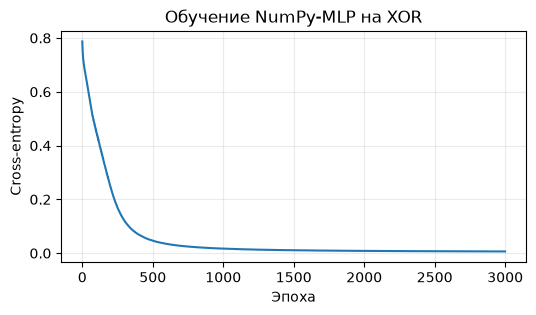

In [10]:
# Листинг 10 — Обучение NumPy-сети на XOR
# XOR — минимальная задача, в которой линейной границы недостаточно.
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=np.float64)
y_xor = np.array([0, 1, 1, 0], dtype=np.int64)
xor_parameters = initialize_numpy_mlp(2, 8, 2, RANDOM_STATE)
 
learning_rate = 0.10
loss_history = []
for epoch in range(3000):
    probabilities, cache = forward_numpy(X_xor, xor_parameters)
    loss = cross_entropy_numpy(probabilities, y_xor, xor_parameters, l2=1e-4)
    gradients = backward_numpy(cache, y_xor, xor_parameters, l2=1e-4)
 
    # Полный градиентный шаг обновляет все параметры сети.
    for name in xor_parameters:
        xor_parameters[name] -= learning_rate * gradients[name]
    loss_history.append(loss)
 
    if (epoch + 1) % 500 == 0:
        print(f"Эпоха {epoch + 1:4d}; loss = {loss:.5f}")
 
# После обучения классы определяются по максимальной вероятности.
xor_probabilities, _ = forward_numpy(X_xor, xor_parameters)
xor_predictions = xor_probabilities.argmax(axis=1)
print("Вероятности:\n", np.round(xor_probabilities, 3))
print("Предсказания:", xor_predictions)
 
plt.figure(figsize=(6, 3))
plt.plot(loss_history)
plt.xlabel("Эпоха")
plt.ylabel("Cross-entropy")
plt.title("Обучение NumPy-MLP на XOR")
plt.grid(alpha=0.25)
plt.show()


In [11]:
# Листинг 11 — Создание DataLoader
def make_loader(X, y, batch_size, shuffle, seed):
    """Преобразует массивы в тензоры и создаёт воспроизводимый DataLoader."""
    # Сначала явно задаём типы: float32 для признаков, long для номеров классов.
    X_tensor = torch.as_tensor(X, dtype=torch.float32)
    y_tensor = torch.as_tensor(y, dtype=torch.long)
    dataset = TensorDataset(X_tensor, y_tensor)
 
    # Отдельный generator делает порядок перемешивания воспроизводимым.
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        generator=generator,
        num_workers=0,
    )
 
 
train_loader = make_loader(X_train, y_train, 64, True, RANDOM_STATE)
val_loader = make_loader(X_val, y_val, 256, False, RANDOM_STATE)


In [12]:
# Листинг 12 — Описание полносвязной сети
class MLP(nn.Module):
    """Один скрытый слой: Linear → ReLU → Dropout → Linear."""
 
    def __init__(self, n_features, n_classes, hidden_size=64, dropout=0.0):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(n_features, hidden_size),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(hidden_size, n_classes),
        )
        self.reset_parameters()
 
    def reset_parameters(self):
        # He-инициализация согласована с ReLU скрытого слоя.
        nn.init.kaiming_normal_(self.network[0].weight, nonlinearity="relu")
        nn.init.zeros_(self.network[0].bias)
        # Для выходного слоя используем Xavier и нулевое смещение.
        nn.init.xavier_uniform_(self.network[3].weight)
        nn.init.zeros_(self.network[3].bias)
 
    def forward(self, X):
        # Возвращаются логиты: CrossEntropyLoss сама применяет LogSoftmax.
        return self.network(X)
 
 
model = MLP(
    n_features=X_train.shape[1],
    n_classes=len(label_encoder.classes_),
    hidden_size=64,
    dropout=0.20,
).to(DEVICE)
print(model)


MLP(
  (network): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [13]:
# Листинг 13 — Оценивание модели без вычисления градиентов
def evaluate_model(model, loader):
    """Возвращает loss, метрики, ответы и вероятности."""
    # Оценивание выполняется единообразно для Validation и Test.
    model.eval()                    # отключаем Dropout
    criterion = nn.CrossEntropyLoss(reduction="sum")
    all_targets, all_predictions, all_probabilities = [], [], []
    total_loss = 0.0
 
    with torch.no_grad():           # граф градиентов при оценивании не нужен
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)
            logits = model(X_batch)
            probabilities = torch.softmax(logits, dim=1)
 
            total_loss += criterion(logits, y_batch).item()
            all_targets.append(y_batch.cpu().numpy())
            all_predictions.append(logits.argmax(dim=1).cpu().numpy())
            all_probabilities.append(probabilities.cpu().numpy())
 
    y_true = np.concatenate(all_targets)
    y_pred = np.concatenate(all_predictions)
    probabilities = np.vstack(all_probabilities)
 
    # ROC-AUC требует присутствия всех классов; поэтому предусмотрена защита.
    try:
        if probabilities.shape[1] == 2:
            auc = roc_auc_score(y_true, probabilities[:, 1])
        else:
            auc = roc_auc_score(
                y_true, probabilities, multi_class="ovr", average="macro"
            )
    except ValueError:
        auc = np.nan
 
    metrics = {
        "loss": total_loss / len(y_true),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
        "roc_auc": auc,
    }
    return metrics, y_true, y_pred, probabilities


In [14]:
# Листинг 14 — Цикл обучения с ранней остановкой
def make_optimizer(model, name, learning_rate, weight_decay):
    """Создаёт optimizer по имени с общей L2-регуляризацией."""
    if name == "SGD":
        return torch.optim.SGD(
            model.parameters(), lr=learning_rate, weight_decay=weight_decay
        )
    if name == "Momentum":
        return torch.optim.SGD(
            model.parameters(), lr=learning_rate, momentum=0.9,
            weight_decay=weight_decay
        )
    if name == "Adam":
        return torch.optim.Adam(
            model.parameters(), lr=learning_rate, weight_decay=weight_decay
        )
    raise ValueError(f"Неизвестный optimizer: {name}")
 
 
def train_model(
    X_train, y_train, X_val, y_val, *, optimizer_name="Adam",
    learning_rate=1e-3, hidden_size=64, dropout=0.0,
    weight_decay=0.0, max_epochs=120, patience=15, seed=1000,
):
    """Обучает MLP и восстанавливает состояние с лучшей validation loss."""
    # Seed фиксируется внутри функции, чтобы сравнивать одинаковую инициализацию.
    set_seed(seed)
    train_loader = make_loader(X_train, y_train, 64, True, seed)
    val_loader = make_loader(X_val, y_val, 256, False, seed)
 
    model = MLP(
        X_train.shape[1], len(np.unique(y_train)), hidden_size, dropout
    ).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = make_optimizer(
        model, optimizer_name, learning_rate, weight_decay
    )
 
    history = {"epoch": [], "train_loss": [], "val_loss": [], "val_f1": []}
    best_state, best_val_loss, epochs_without_improvement = None, np.inf, 0
 
    for epoch in range(1, max_epochs + 1):
        model.train()               # Dropout включён только на обучении
        loss_sum, object_count = 0.0, 0
        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)
 
            optimizer.zero_grad()   # не накапливаем градиенты прошлой итерации
            logits = model(X_batch)
            loss = criterion(logits, y_batch)
            loss.backward()         # автоматический BackProp
            optimizer.step()
 
            loss_sum += loss.item() * len(y_batch)
            object_count += len(y_batch)
 
        val_metrics, _, _, _ = evaluate_model(model, val_loader)
        history["epoch"].append(epoch)
        history["train_loss"].append(loss_sum / object_count)
        history["val_loss"].append(val_metrics["loss"])
        history["val_f1"].append(val_metrics["f1_macro"])
 
        # Сохраняем параметры только при реальном улучшении validation loss.
        if val_metrics["loss"] < best_val_loss - 1e-5:
            best_val_loss = val_metrics["loss"]
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            break
 
    model.load_state_dict(best_state)
    final_val_metrics, _, _, _ = evaluate_model(model, val_loader)
    return model, history, final_val_metrics


In [15]:
# Листинг 15 — Первое обучение MLP с Adam
# Эта конфигурация служит отправной точкой, а не окончательным результатом.
# Все гиперпараметры явно записаны, поэтому запуск можно воспроизвести.
adam_model, adam_history, adam_val_metrics = train_model(
    X_train,
    y_train,
    X_val,
    y_val,
    optimizer_name="Adam",
    learning_rate=1e-3,
    hidden_size=64,
    dropout=0.0,
    weight_decay=0.0,
    max_epochs=120,
    patience=15,
    seed=RANDOM_STATE,
)
 
print("Validation-метрики MLP:")
print(pd.Series(adam_val_metrics).round(4))
print("Validation macro-F1 baseline:", round(baseline_result["macro_f1"], 4))


Validation-метрики MLP:
loss               0.1665
accuracy           0.9575
precision_macro    0.9577
recall_macro       0.9575
f1_macro           0.9573
roc_auc            0.9980
dtype: float64
Validation macro-F1 baseline: 0.9327


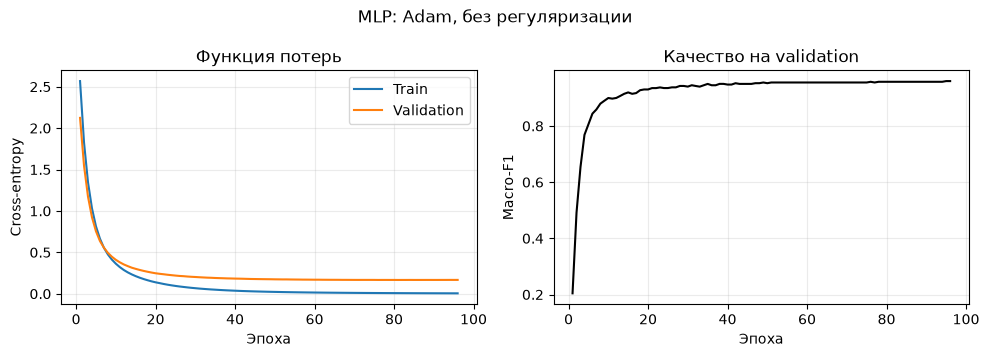

In [16]:
# Листинг 16 — Кривые обучения
def plot_history(history, title):
    """Показывает динамику loss и validation macro-F1."""
    # На первом графике сравниваем обучение и обобщение модели.
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
 
    axes[0].plot(history["epoch"], history["train_loss"], label="Train")
    axes[0].plot(history["epoch"], history["val_loss"], label="Validation")
    axes[0].set_xlabel("Эпоха")
    axes[0].set_ylabel("Cross-entropy")
    axes[0].set_title("Функция потерь")
    axes[0].legend()
    axes[0].grid(alpha=0.25)
 
    # Второй график показывает целевую метрику выбора конфигурации.
    axes[1].plot(history["epoch"], history["val_f1"], color="black")
    axes[1].set_xlabel("Эпоха")
    axes[1].set_ylabel("Macro-F1")
    axes[1].set_title("Качество на validation")
    axes[1].grid(alpha=0.25)
 
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
 
 
plot_history(adam_history, "MLP: Adam, без регуляризации")


In [17]:
# Листинг 17 — SGD, Momentum и Adam при фиксированной архитектуре
# Для каждого optimizer заранее задаём разумный learning rate.
# Архитектура, seed, разбиение и правило остановки остаются одинаковыми.
optimizer_settings = {
    "SGD": 0.03,
    "Momentum": 0.02,
    "Adam": 0.001,
}
optimizer_rows = []
optimizer_runs = {}
 
for optimizer_name, learning_rate in optimizer_settings.items():
    model, history, metrics = train_model(
        X_train,
        y_train,
        X_val,
        y_val,
        optimizer_name=optimizer_name,
        learning_rate=learning_rate,
        hidden_size=64,
        dropout=0.0,
        weight_decay=0.0,
        max_epochs=120,
        patience=15,
        seed=RANDOM_STATE,       # одинаковая начальная инициализация
    )
    optimizer_runs[optimizer_name] = {
        "model": model,
        "history": history,
        "metrics": metrics,
    }
    optimizer_rows.append({
        "optimizer": optimizer_name,
        "learning_rate": learning_rate,
        "epochs": len(history["epoch"]),
        "best_val_loss": min(history["val_loss"]),
        "val_macro_f1": metrics["f1_macro"],
    })
 
optimizer_results = pd.DataFrame(optimizer_rows).sort_values(
    "val_macro_f1", ascending=False
)
best_optimizer = optimizer_results.iloc[0]["optimizer"]
best_learning_rate = optimizer_settings[best_optimizer]
print(optimizer_results.round(4))
print("Выбран optimizer:", best_optimizer)


  optimizer  learning_rate  epochs  best_val_loss  val_macro_f1
2      Adam          0.001      96         0.1665        0.9573
1  Momentum          0.020      43         0.1823        0.9525
0       SGD          0.030     120         0.1830        0.9474
Выбран optimizer: Adam


In [18]:
# Листинг 18 — Сравнение Dropout и L2-регуляризации
# Регуляризацию исследуем уже с выбранным на validation оптимизатором.
# Одновременно меняется только один механизм регуляризации.
regularization_settings = {
    "Без регуляризации": {"dropout": 0.0, "weight_decay": 0.0},
    "L2": {"dropout": 0.0, "weight_decay": 1e-4},
    "Dropout": {"dropout": 0.25, "weight_decay": 0.0},
}
regularization_rows = []
regularization_runs = {}
 
for regularization_name, config in regularization_settings.items():
    model, history, metrics = train_model(
        X_train,
        y_train,
        X_val,
        y_val,
        optimizer_name=best_optimizer,
        learning_rate=best_learning_rate,
        hidden_size=64,
        dropout=config["dropout"],
        weight_decay=config["weight_decay"],
        max_epochs=120,
        patience=15,
        seed=RANDOM_STATE,
    )
    regularization_runs[regularization_name] = {
        "model": model,
        "history": history,
        "metrics": metrics,
    }
    regularization_rows.append({
        "regularization": regularization_name,
        "dropout": config["dropout"],
        "weight_decay": config["weight_decay"],
        "epochs": len(history["epoch"]),
        "val_loss": metrics["loss"],
        "val_macro_f1": metrics["f1_macro"],
    })
 
regularization_results = pd.DataFrame(regularization_rows).sort_values(
    "val_macro_f1", ascending=False
)
best_regularization = regularization_results.iloc[0]["regularization"]
print(regularization_results.round(4))
print("Выбрана конфигурация:", best_regularization)



      regularization  dropout  weight_decay  epochs  val_loss  val_macro_f1
2            Dropout     0.25        0.0000     109    0.1385        0.9600
1                 L2     0.00        0.0001     113    0.1645        0.9598
0  Без регуляризации     0.00        0.0000      96    0.1665        0.9573
Выбрана конфигурация: Dropout


In [19]:
# Листинг 19 — Переобучение выбранной конфигурации на Train+Validation
# Число эпох берём из лучшей validation-точки выбранного запуска.
selected_run = regularization_runs[best_regularization]
best_epoch = int(np.argmin(selected_run["history"]["val_loss"]) + 1)
selected_config = regularization_settings[best_regularization]
 
# После завершения выбора preprocessing можно переобучить на Train+Validation.
# Сохраняем схему обработки: StandardScaler или ColumnTransformer.
final_preprocessor = copy.deepcopy(preprocessor)
X_trainval = np.asarray(
    final_preprocessor.fit_transform(X_trainval_raw), dtype=np.float32
)
X_test_final = np.asarray(
    final_preprocessor.transform(X_test_raw), dtype=np.float32
)
 
final_label_encoder = LabelEncoder()
y_trainval = final_label_encoder.fit_transform(y_trainval_raw).astype(np.int64)
y_test_final = final_label_encoder.transform(y_test_raw).astype(np.int64)
 
def fit_fixed_epochs(X, y, epochs, *, seed):
    """Обучает финальную сеть фиксированное число эпох без test-остановки."""
    set_seed(seed)
    loader = make_loader(X, y, 64, True, seed)
    model = MLP(
        X.shape[1], len(np.unique(y)), hidden_size=64,
        dropout=selected_config["dropout"]
    ).to(DEVICE)
    optimizer = make_optimizer(
        model, best_optimizer, best_learning_rate,
        selected_config["weight_decay"]
    )
    criterion = nn.CrossEntropyLoss()
 
    for _ in range(epochs):
        model.train()
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(X_batch), y_batch)
            loss.backward()
            optimizer.step()
    return model
 
 
final_model = fit_fixed_epochs(
    X_trainval, y_trainval, best_epoch, seed=RANDOM_STATE
)
print("Финальное число эпох:", best_epoch)



Финальное число эпох: 94


                model  accuracy  macro_f1
0  LogisticRegression    0.9650    0.9649
1                 MLP    0.9825    0.9824
loss               0.0859
accuracy           0.9825
precision_macro    0.9831
recall_macro       0.9825
f1_macro           0.9824
roc_auc            0.9989
dtype: float64
              precision    recall  f1-score   support

           1       0.98      1.00      0.99        40
           2       0.95      1.00      0.98        40
           3       1.00      1.00      1.00        40
           4       1.00      0.90      0.95        40
           5       1.00      0.97      0.99        40
           6       0.95      1.00      0.98        40
           7       1.00      1.00      1.00        40
           8       0.98      1.00      0.99        40
           9       1.00      0.97      0.99        40
          10       0.97      0.97      0.97        40

    accuracy                           0.98       400
   macro avg       0.98      0.98      0.98       400

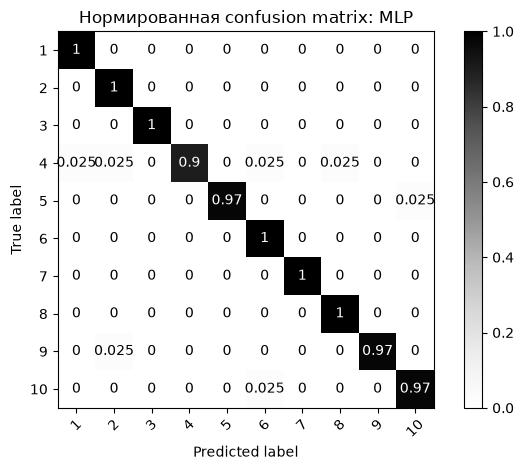

In [20]:
# Листинг 20 — Однократная оценка на Test
# Только теперь test впервые используется для вычисления итоговых метрик.
test_loader = make_loader(
    X_test_final, y_test_final, 256, False, RANDOM_STATE
)
test_metrics, test_true, test_pred, test_probabilities = evaluate_model(
    final_model, test_loader
)
 
# Линейный baseline также переобучаем на той же части Train+Validation.
final_baseline = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
final_baseline.fit(X_trainval, y_trainval)
baseline_test_pred = final_baseline.predict(X_test_final)
 
comparison = pd.DataFrame([
    {
        "model": "LogisticRegression",
        "accuracy": accuracy_score(y_test_final, baseline_test_pred),
        "macro_f1": f1_score(y_test_final, baseline_test_pred, average="macro"),
    },
    {
        "model": "MLP",
        "accuracy": test_metrics["accuracy"],
        "macro_f1": test_metrics["f1_macro"],
    },
])
print(comparison.round(4))
print(pd.Series(test_metrics).round(4))
print(classification_report(
    test_true,
    test_pred,
    target_names=[str(value) for value in final_label_encoder.classes_],
    zero_division=0,
))
 
# Нормировка по строкам показывает долю объектов каждого истинного класса.
ConfusionMatrixDisplay.from_predictions(
    test_true,
    test_pred,
    display_labels=final_label_encoder.classes_,
    normalize="true",
    cmap="Greys",
    xticks_rotation=45,
)
plt.title("Нормированная confusion matrix: MLP")
plt.tight_layout()
plt.show()


In [23]:
# Листинг 21 — Таблица и визуализация ошибок

# Уверенность — максимальная предсказанная вероятность класса.
error_indices = np.flatnonzero(test_true != test_pred)
error_table = pd.DataFrame({
    "test_index": error_indices,
    "true": final_label_encoder.inverse_transform(test_true[error_indices]),
    "predicted": final_label_encoder.inverse_transform(test_pred[error_indices]),
    "confidence": test_probabilities[error_indices].max(axis=1),
}).sort_values("confidence", ascending=False)
 

raw_errors = X_test_raw.iloc[error_table["test_index"].to_numpy()].reset_index(drop=True)

error_table_full = pd.concat(
    [error_table.reset_index(drop=True), raw_errors],
    axis=1,
)

print("Число ошибок:", len(error_table_full))
print(error_table_full.head(10))
 

Число ошибок: 7
   test_index  true  predicted  confidence       att1       att2      att3  \
0         385     5         10    0.978571  -3.185716  -5.169368 -4.394968   
1         231     4          1    0.968926  -6.035366 -10.678077  1.473566   
2         303     4          2    0.897095   5.363024   5.736277  2.384048   
3         308    10          6    0.679649   1.835815 -11.605419  1.399250   
4         369     4          8    0.679326  14.225326   5.820617  3.543279   
5         315     9          2    0.616598   1.774103  -3.319655  1.988277   
6         370     4          6    0.333126  -4.371149   4.429170  1.761223   

       att4      att5      att6  ...     att55     att56     att57     att58  \
0  7.903034  5.289021  2.059289  ...  0.908425  0.551537 -0.072634  0.264875   
1  6.008083 -5.200163  9.328547  ... -1.031310  1.497898  1.275771 -1.096247   
2  9.232138  5.200172  2.759709  ...  2.008732 -0.479582  0.350035 -0.385482   
3  5.410382  1.828326 -0.830601  ... -0